# 02 - Seaborn Statistical Plots
Seaborn works on top of matplotlib and gives nicer statistical charts with less code.

We create our own small dataset, so no internet is needed.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(0)
sns.set_theme(style='whitegrid')

n = 200
df = pd.DataFrame({
    'bill':   np.random.uniform(10, 60, n).round(2),
    'day':    np.random.choice(['Thu', 'Fri', 'Sat', 'Sun'], n),
    'time':   np.random.choice(['Lunch', 'Dinner'], n),
    'smoker': np.random.choice(['Yes', 'No'], n),
    'size':   np.random.randint(1, 6, n),
})
df['tip'] = (df['bill'] * np.random.uniform(0.05, 0.25, n)).round(2)
df.head()

,bill,day,time,smoker,size,tip
0,37.44,Sat,Lunch,No,3,4.68
1,45.76,Sun,Lunch,Yes,4,8.34
2,40.14,Sat,Dinner,No,5,7.03
3,37.24,Thu,Dinner,Yes,1,8.67
4,31.18,Sun,Dinner,Yes,3,5.75


## Distribution plots

### 1. Histogram + KDE

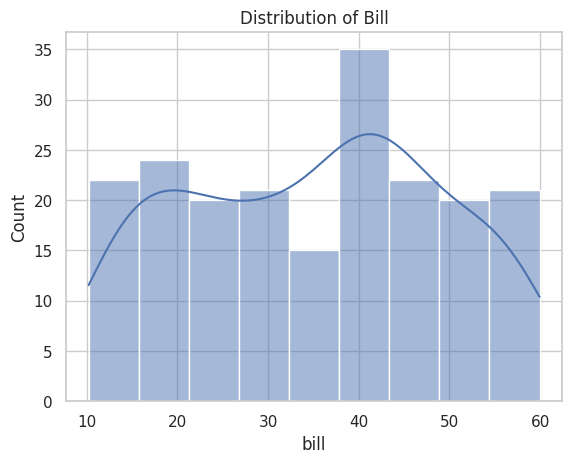

In [2]:
sns.histplot(data=df, x='bill', kde=True)
plt.title('Distribution of Bill')
plt.show()

### 2. KDE plot (smooth curve) split by group

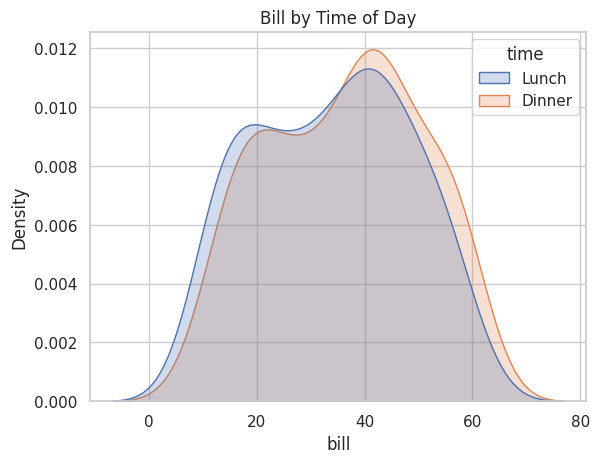

In [3]:
sns.kdeplot(data=df, x='bill', hue='time', fill=True)
plt.title('Bill by Time of Day')
plt.show()

### 3. ECDF plot
Shows the % of values below each point.

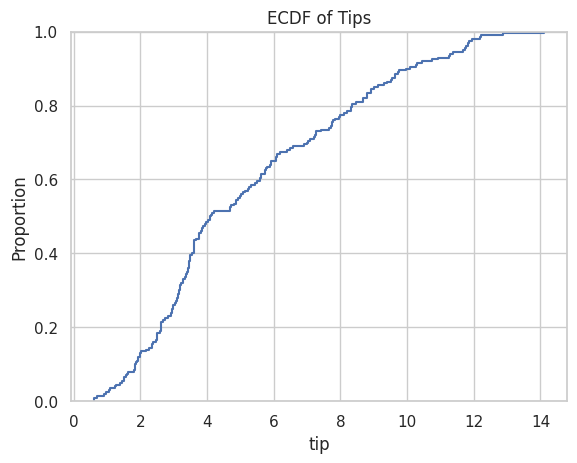

In [4]:
sns.ecdfplot(data=df, x='tip')
plt.title('ECDF of Tips')
plt.show()

## Categorical plots

### 4. Count plot

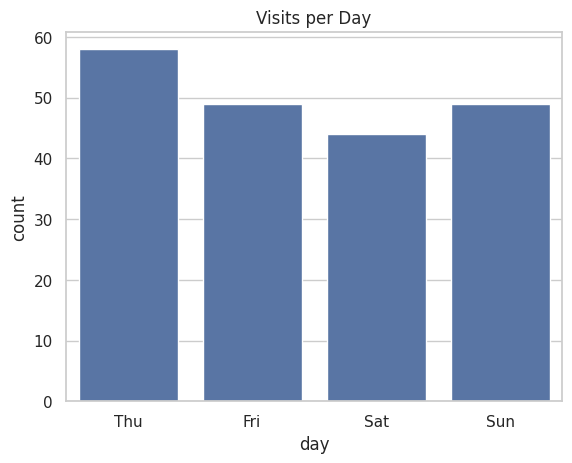

In [5]:
sns.countplot(data=df, x='day', order=['Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Visits per Day')
plt.show()

### 5. Bar plot (average + confidence interval)

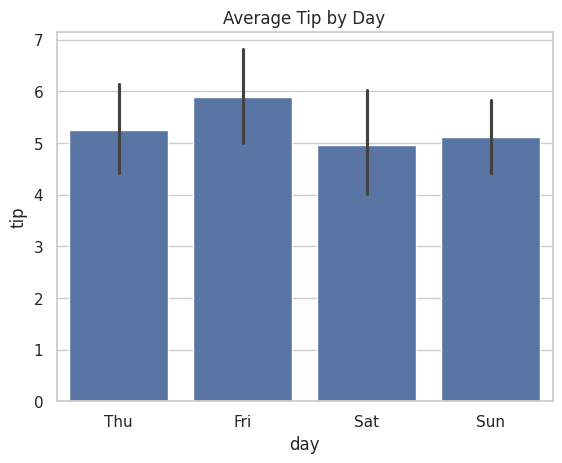

In [6]:
sns.barplot(data=df, x='day', y='tip', order=['Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Average Tip by Day')
plt.show()

### 6. Box plot

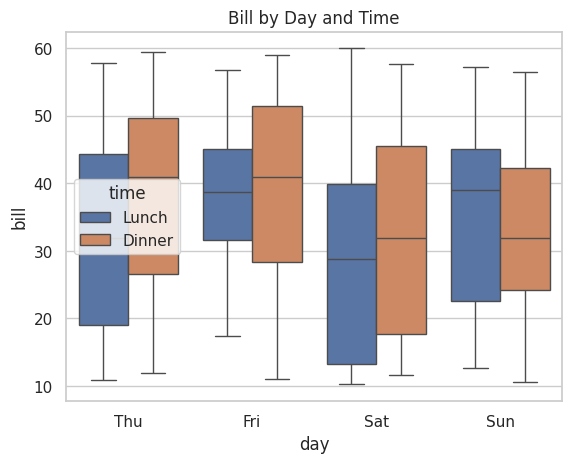

In [7]:
sns.boxplot(data=df, x='day', y='bill', hue='time', order=['Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Bill by Day and Time')
plt.show()

### 7. Violin plot
A box plot plus the shape of the distribution.

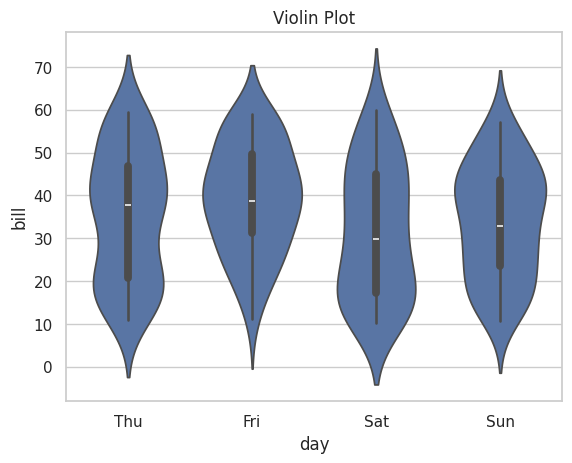

In [8]:
sns.violinplot(data=df, x='day', y='bill', order=['Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Violin Plot')
plt.show()

### 8. Strip plot (every dot is a row)

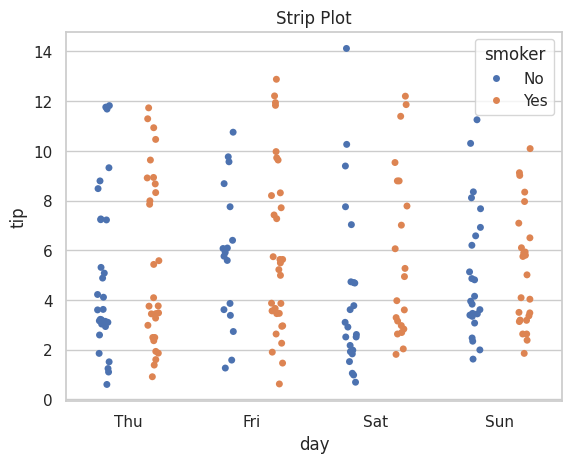

In [9]:
sns.stripplot(data=df, x='day', y='tip', hue='smoker', dodge=True, order=['Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Strip Plot')
plt.show()

### 9. Swarm plot (dots do not overlap)

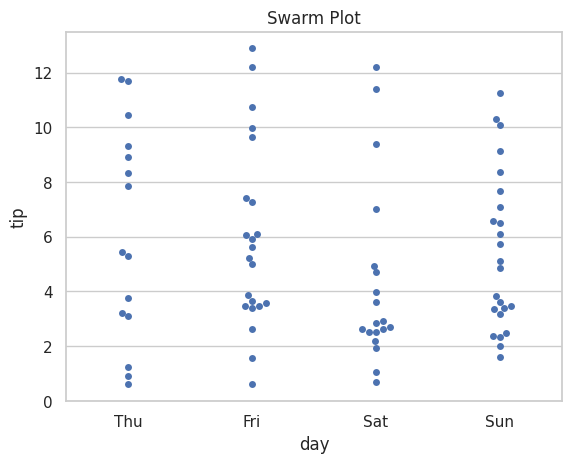

In [10]:
sns.swarmplot(data=df.sample(80, random_state=1), x='day', y='tip', order=['Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Swarm Plot')
plt.show()

## Relationships between numbers

### 10. Scatter plot with groups

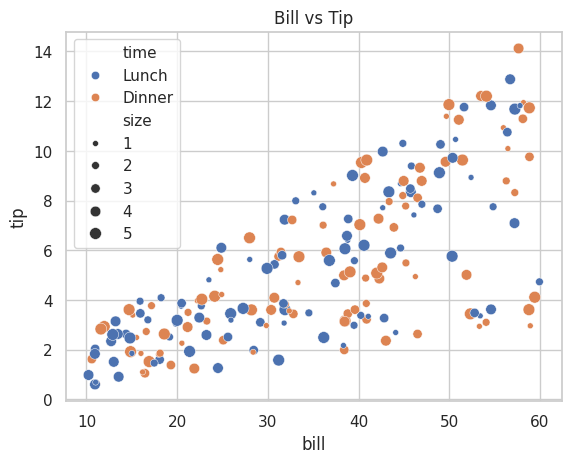

In [11]:
sns.scatterplot(data=df, x='bill', y='tip', hue='time', size='size')
plt.title('Bill vs Tip')
plt.show()

### 11. Regression plot (scatter + trend line)

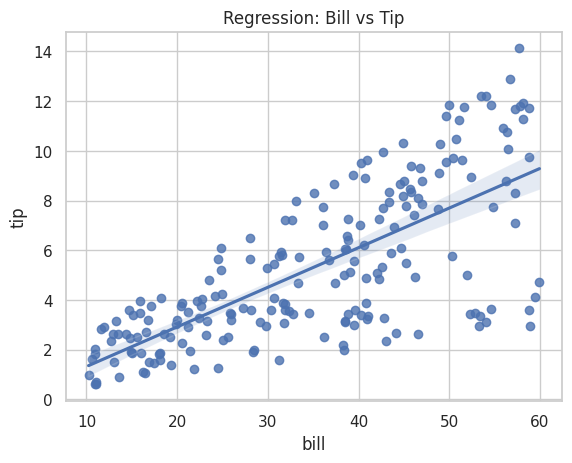

In [12]:
sns.regplot(data=df, x='bill', y='tip')
plt.title('Regression: Bill vs Tip')
plt.show()

### 12. Joint plot (scatter + histograms)

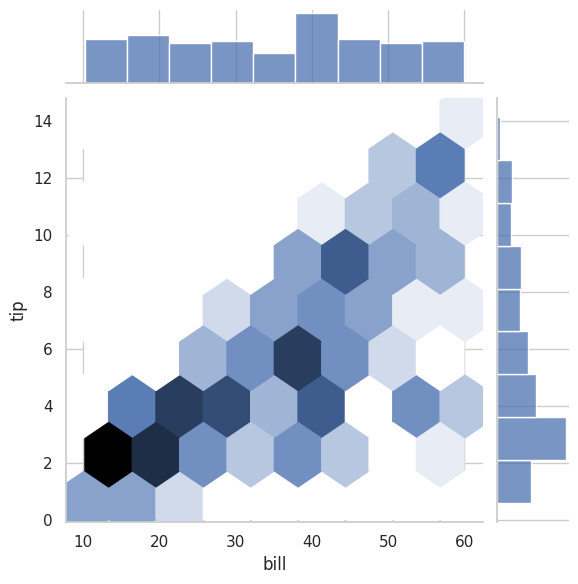

In [13]:
sns.jointplot(data=df, x='bill', y='tip', kind='hex')
plt.show()

## Heatmaps

### 13. Correlation heatmap

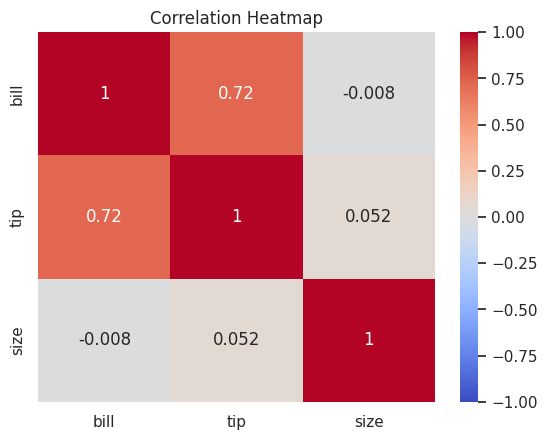

In [14]:
corr = df[['bill', 'tip', 'size']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

### 14. Pivot-table heatmap

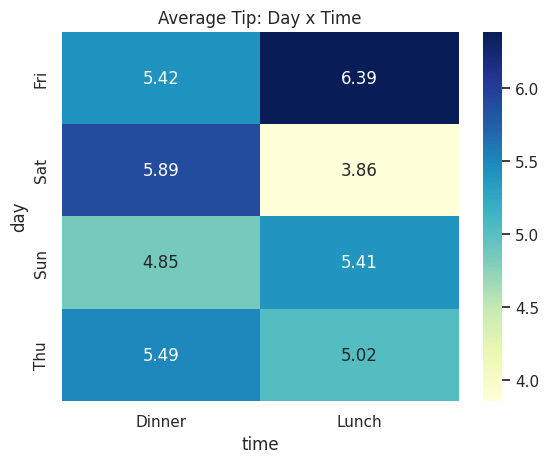

In [15]:
pivot = df.pivot_table(index='day', columns='time', values='tip', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Average Tip: Day x Time')
plt.show()

## Pair plot
Plots every numeric column against every other.

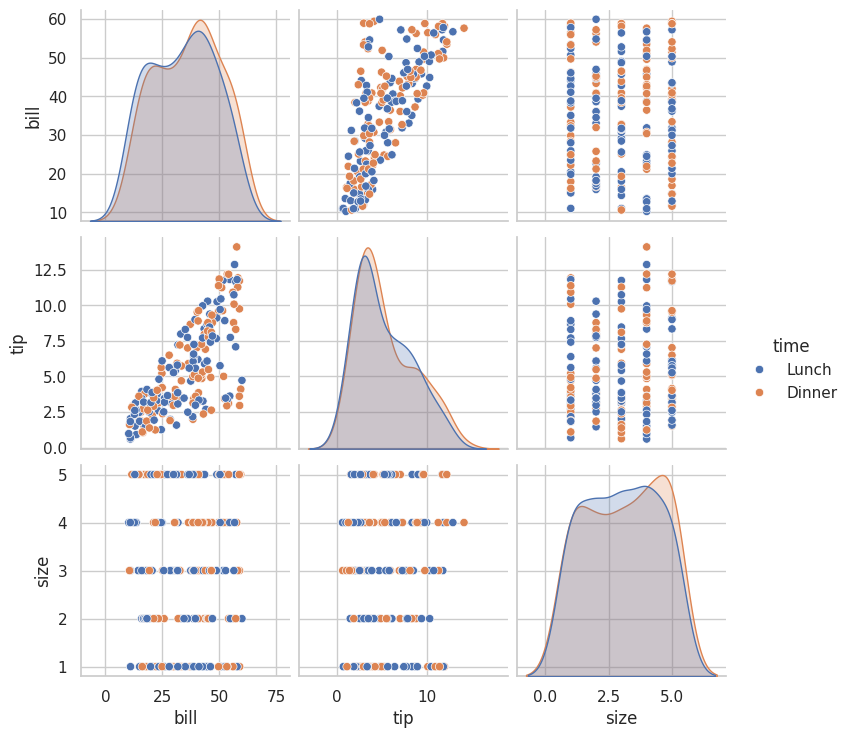

In [16]:
sns.pairplot(df[['bill', 'tip', 'size', 'time']], hue='time')
plt.show()

## Facet grid (small multiples)

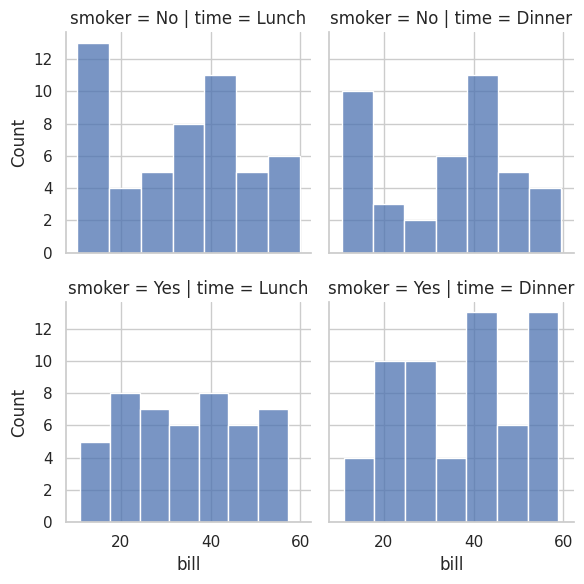

In [17]:
g = sns.FacetGrid(df, col='time', row='smoker')
g.map_dataframe(sns.histplot, x='bill')
plt.show()

## Statistical annotations
Add a correlation value and group means to the chart.

Correlation r = 0.72, p-value = 0.0000


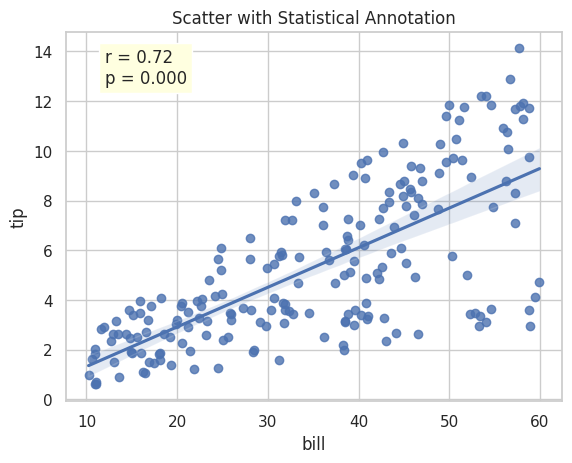

In [18]:
from scipy import stats

r, p = stats.pearsonr(df['bill'], df['tip'])
print(f'Correlation r = {r:.2f}, p-value = {p:.4f}')

sns.regplot(data=df, x='bill', y='tip')
plt.text(12, df['tip'].max() * 0.9, f'r = {r:.2f}\np = {p:.3f}',
         bbox=dict(facecolor='lightyellow'))
plt.title('Scatter with Statistical Annotation')
plt.show()

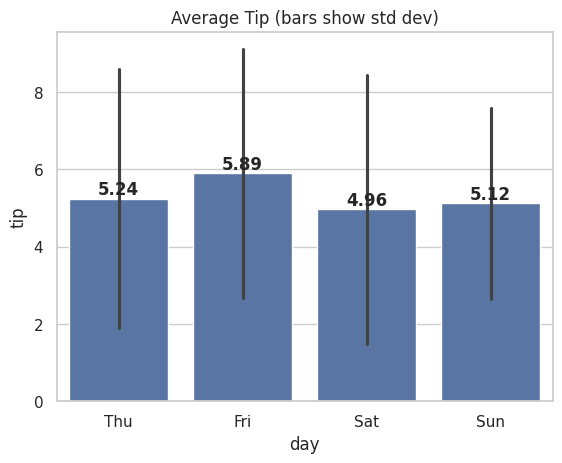

In [19]:
# Annotate group means on a bar plot
order = ['Thu', 'Fri', 'Sat', 'Sun']
ax = sns.barplot(data=df, x='day', y='tip', order=order, errorbar='sd')
for i, d in enumerate(order):
    m = df[df['day'] == d]['tip'].mean()
    ax.text(i, m + 0.1, f'{m:.2f}', ha='center', fontweight='bold')
plt.title('Average Tip (bars show std dev)')
plt.show()

In [20]:
# Simple t-test: do lunch and dinner tips differ?
lunch = df[df['time'] == 'Lunch']['tip']
dinner = df[df['time'] == 'Dinner']['tip']
t, p = stats.ttest_ind(lunch, dinner)
print(f't = {t:.2f}, p = {p:.3f}')
print('Significant difference' if p < 0.05 else 'No significant difference (p >= 0.05)')

t = -0.44, p = 0.659
No significant difference (p >= 0.05)
